# 11. Why does the autoencoder win on the penicillin batches?

**The one deep-model win** (notebook 09): on IndPenSim, the autoencoder catches 0.64 of faulty readings against 0.45 for the best simple detector. The follow-up checks (notebook 09, section 11b) showed that all of the gain comes from three batches, 91, 95 and 97. All three carry the same fault, the **substrate feed fault**: the sugar feed is held at 2 L/h from 20 to 30 hours, then at 20 L/h from 76 to 92 hours and from 200 to 214 hours.

**This notebook asks why.** It is explanation only. Nothing here changes a setting of the headline or its result. Every model below is fitted on the same 60 fit batches, with the same held-aside batches, and judged with the same alarm line (the 30 line batches).

**Fixed before computing** (the design is also written in `adlab/deepdive.py`):

1. **Locate the win.** For the three batches' faulty readings: when the autoencoder alarms and the best simple detector (the curved-link residual) does not, and which sensor's error drives those alarms. The autoencoder studied is seed 0, the one whose network is examined. The same is done for PCA scored like the autoencoder.
2. **Look at it.** Normal readings of the driving sensors and their partners, coloured by stage, with the faulty readings on top. Also the normal readings as the autoencoder's bottleneck sees them and as PCA's first two components see them. Each shape is labelled: corner or ceiling, switch, stage change, interaction between two sensors, or smooth curve.
3. **Test which ingredient it is.** Each test is a straight-line model given one extra ingredient, scored exactly like the autoencoder:
    - corners: PCA on the sensors plus the kinked check's hinge terms;
    - stages: a separate PCA per tenth of the batch;
    - strategies: a separate PCA per control strategy;
    - switches: PCA plus a yes/no column for each controller output that sits at its lowest or highest value in 5-95% of the fit readings.

   Then, for **which sensors**, the autoencoder trained on the 9 measurements only, then on the 11 controller outputs only. Every PCA keeps the directions holding 90% of its inputs' variance. The test that closes most of the gap to the autoencoder names the ingredient.
4. **Write it up**, ending with a short recipe for artificial data that should reproduce it (part D builds on it).

**Words used here.** A *controller output* is a setting the control system moves (a feed rate, the air flow); a *measurement* is a reading of the process (oxygen in the exhaust gas, volume). A *scaled error* is a sensor's error divided by its own 99% error line, so 1 means "at its line". The *alarm line* is set on the scores, the largest scaled error across sensors.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import deepdive, explore, followup, indpensim, plots

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
followup.ips_by_batch()[["fault type", "timing", "faulty readings", "Autoencoder", "Curved-link residual",
                         "PCA, scored like the autoencoder", "autoencoder minus curved-link, points"]]

,fault type,timing,faulty readings,Autoencoder,Curved-link residual,"PCA, scored like the autoencoder","autoencoder minus curved-link, points"
batch,,,,,,,
91,substrate feed,A,203,0.292,0.02,0,27.258
92,base flow,B,122,0.828,0.787,0,4.098
93,coolant flow,C,101,0.851,0.842,0.723,0.99
94,aeration,D,72,1,1,1,0
95,substrate feed,E,188,0.321,0,0,32.092
96,coolant flow,C,101,0.683,0.693,0.683,-0.99
97,substrate feed,A,203,0.521,0.01,0,51.067
98,base flow,B,122,0.866,0.77,0,9.563
99,aeration,D,72,1,1,1,0


## 1. Where the win is

When, in the three batches, does the autoencoder alarm and the curved-link not? The faulty readings fall in three stretches, each a different setting of the sugar feed.

In [2]:
deepdive.when_table()

faulty readings            stage  \
stretch                        batch                                     
20-30 h (sugar feed held at 2) 91                  51    0-10%, 10-20%   
                               95                  51    0-10%, 10-20%   
                               97                  51    0-10%, 10-20%   
76-92 h (held at 20)           91                  81   20-30%, 30-40%   
                               95                  81   30-40%, 40-50%   
                               97                  81   30-40%, 40-50%   
200-214 h (held at 20)         91                  71   70-80%, 80-90%   
                               95                  56          90-100%   
                               97                  71  80-90%, 90-100%   

                                      autoencoder  curved-link  \
stretch                        batch                             
20-30 h (sugar feed held at 2) 91               0            0   
                               95               0            0   
                               97               0            0   
76-92 h (held at 20)           91               1            0   
                               95               1            0   
                               97               1            0   
200-214 h (held at 20)         91           0.014        0.056   
                               95               0            0   
                               97           0.211        0.028   

                                      PCA scored alike  autoencoder only  \
stretch                        batch                                       
20-30 h (sugar feed held at 2) 91                    0                 0   
                               95                    0                 0   
                               97                    0                 0   
76-92 h (held at 20)           91                    0                 1   
                               95                    0                 1   
                               97                    0                 1   
200-214 h (held at 20)         91                    0             0.014   
                               95                    0                 0   
                               97                    0             0.183   

                                      unseen value check (round 3)  \
stretch                        batch                                 
20-30 h (sugar feed held at 2) 91                                1   
                               95                                1   
                               97                                1   
76-92 h (held at 20)           91                                1   
                               95                                1   
                               97                                1   
200-214 h (held at 20)         91                                1   
                               95                                1   
                               97                                1   

                                      nearest normal reading (round 3)  
stretch                        batch                                    
20-30 h (sugar feed held at 2) 91                                0.588  
                               95                                 0.51  
                               97                                 0.51  
76-92 h (held at 20)           91                                    1  
                               95                                    1  
                               97                                    1  
200-214 h (held at 20)         91                                0.986  
                               95                                0.982  
                               97                                0.986

*Round 3: the last two columns are two schedule-aware simple checks (notebook 09, section 12), added after everything in this notebook; section 6 discusses them.*

**What this shows. The whole win is one stretch: 76 to 92 hours, when the sugar feed is held at 20 L/h** (20-50% of the way through the batch). There the autoencoder alarms on **every** faulty reading of all three batches. The curved-link and PCA scored alike alarm on none. In the first stretch (sugar feed held at 2 L/h, 20-30 hours) nothing alarms. In the last (held at 20 L/h again, 200-214 hours) the autoencoder catches a fifth of batch 97 and almost nothing of the others.

Which sensor drives those alarms? At each of the 257 readings where the autoencoder alarms and the curved-link does not, the sensor with the largest scaled error. Beside it, PCA scored alike on the same readings.

In [3]:
drivers = deepdive.drivers()
print("Readings where the autoencoder alarms and the curved-link does not:", drivers.attrs["readings"])
drivers

Readings where the autoencoder alarms and the curved-link does not: 257


,autoencoder: share of these alarms it drives,autoencoder: mean scaled error,PCA scored alike: share it would drive,PCA scored alike: mean scaled error,curved-link: mean scaled error (added)
sensor,,,,,
sugar feed,0.724,2.072,0.027,0.614,1.264
volume,0.257,1.499,0.086,0.321,0.374
pH,0.016,1.459,0,0.044,0.265
heating water,0.004,0.476,0,0.351,0.339
weight,0,1.087,0,0.292,0.263
dissolved oxygen,0,0.34,0,0.179,0.115
oxygen uptake,0,0.149,0.004,0.485,0.573
temperature,0,0.167,0,0.413,0.178
O2 off-gas,0,0.613,0,0.152,0.919


**What this shows.** **The sugar feed drives 72% of these alarms, and the volume 26%.** On these readings the autoencoder's sugar-feed error is on average 2.1 times its line, the volume's 1.5 and the pH's 1.5. PCA scored alike sees the same readings as nearly normal: its sugar-feed error is 0.6 of its line. The autoencoder looks at one moment at a time, so this is a relation between sensors **at the same moment**: the sugar feed of 20 L/h does not fit the other readings of that moment.

*Added after these first results:* the curved-link detector's own scaled errors (last column). It does see the sugar feed as off: 1.3 times its line on average. Yet it alarms on none of these readings. The two tables below show why: its lines are set differently.

*Added after the first results.* Each model's 99% error line per sensor (standardised units), and each model's alarm line in units of scaled error.

In [4]:
display(deepdive.error_scales().loc[["sugar feed", "volume", "pH", "weight"]])
deepdive.alarm_lines()

,autoencoder,PCA scored alike,curved-link
sugar feed,1.019,1.499,1.593
volume,0.342,0.522,0.206
pH,0.767,11.521,2.438
weight,0.375,0.492,0.198


,"line, all 30 line batches","99th percentile, recipe line batches","99th percentile, operator line batches","99th percentile, APC line batches"
autoencoder,1.763,1.592,2.14,1.09
PCA scored alike,1.725,1.412,1.945,1.393
curved-link,2.765,2.551,3.449,2.468


**What this shows.** In raw size, the curved-link's sugar-feed error on these readings (about 2.0 standardised units) is close to the autoencoder's (2.1). But on normal data the curved-link predicts the sugar feed less tightly: its 99% line is 1.6 units against the autoencoder's 1.0. Its alarm line is also higher, at 2.8 scaled units against 1.8. **So the curved-link sees the fault about as large as the autoencoder does, but its normal errors on the sugar feed are wider, and the fault does not stand out.**

Why are its normal errors wider? The curved-link predicts each sensor from the *other* sensors. Across the three control strategies (operators vary the feed), the other sensors say less about the sugar feed. The autoencoder rebuilds each sensor through a narrow bottleneck from *all* the sensors, its own included. Section 3 tests whether scoring is the difference: the curved-link scored exactly like the autoencoder.

## 2. What it looks like

*Fixed before drawing:* the sugar feed against its best single partner among the controller outputs (the oil flow) and against the dilution water; the third pair of that trio (oil flow against dilution water); the sugar feed against its best single partner among all sensors (the CO2 evolution rate); the volume (the second driver) against the sugar feed; and the sugar feed against the air flow. Normal readings of the 60 fit batches, every third reading, coloured by tenth of the batch (light early, dark late). Orange crosses: the 257 faulty readings where the autoencoder alarms and the curved-link does not. Readings with few distinct values are spread a little sideways so that the dots can be seen.

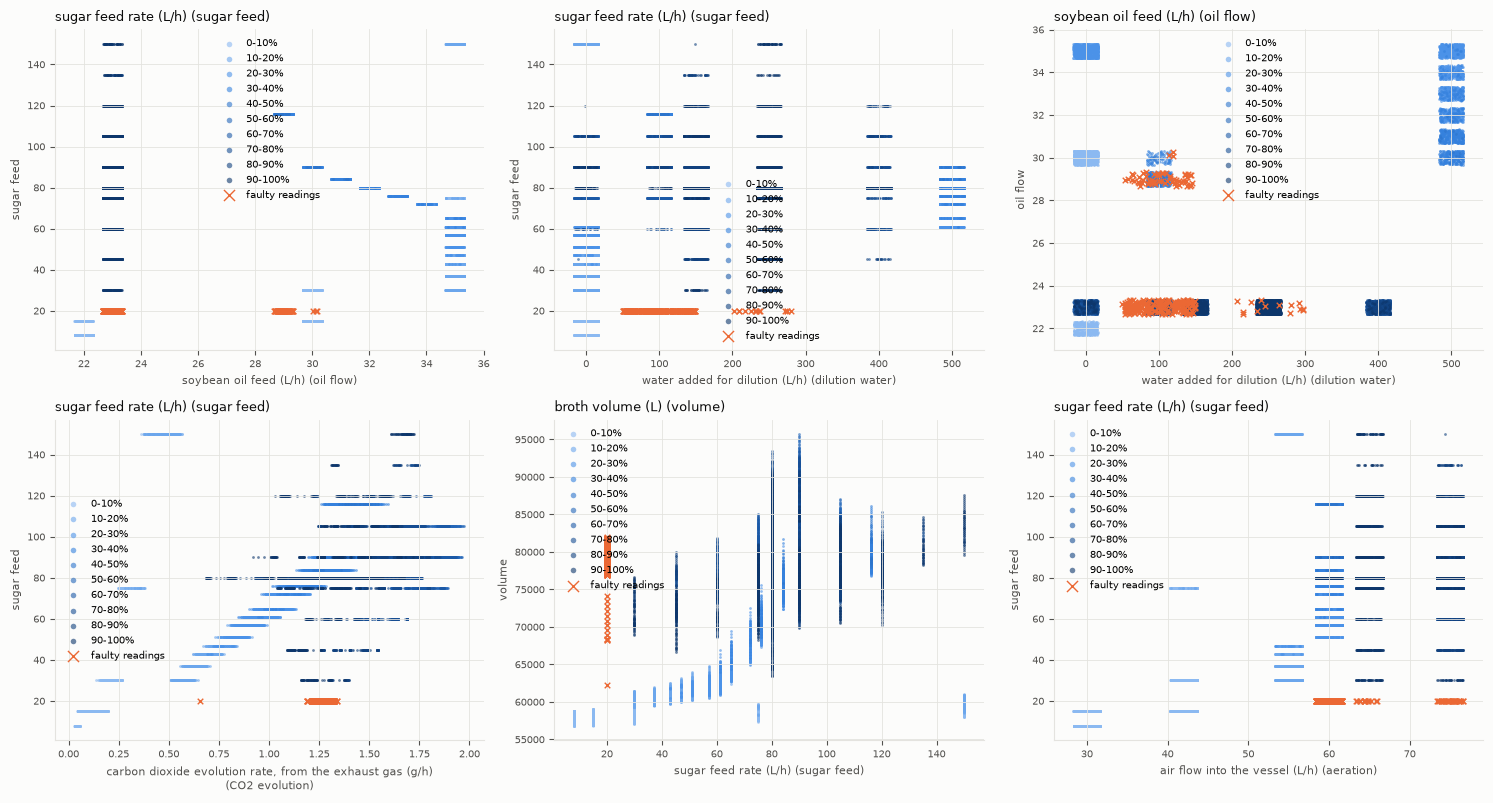

In [5]:
normal, stage, faulty, faulty_batch = deepdive.normal_and_faulty()
pairs = [("sugar feed", "oil flow"), ("sugar feed", "dilution water"), ("oil flow", "dilution water"),
         ("sugar feed", "CO2 evolution"), ("volume", "sugar feed"), ("sugar feed", "aeration")]
describe = {c: f"{indpensim.INFO[c]} ({c})" for c in indpensim.CHANNELS}
tenths = {k: f"{10 * k}-{10 * k + 10}%" for k in range(10)}
plots.scatter_with_faults(normal, stage, faulty, pairs, indpensim.CHANNELS, describe, tenths, every=3, across=3);

**What this shows.** The controller outputs do not move smoothly: each steps through a few fixed values. Together they sit on **separate islands**, one for each combination of recipe steps. The faulty readings land **between** the islands, in combinations that never occur in normal batches: a sugar feed of 20 L/h with an oil flow of 23 or 29 L/h, with a dilution water flow of 50 to 300 L/h, or with an air flow of 60 or 75. Seen one at a time, every one of these values is inside its normal range.

| Pair | Shape |
| --- | --- |
| sugar feed against oil flow | **stage change**: islands, one per combination of recipe steps |
| sugar feed against dilution water | **stage change**: islands |
| oil flow against dilution water | **stage change**: islands |
| sugar feed against CO2 evolution | **smooth curve** early in the batch (the sugar feed is raised as the culture grows), then **stage change** (separate bands) |
| volume against sugar feed | **stage change**: the volume grows within each sugar-feed step |
| sugar feed against air flow | **stage change**: islands |

None of them is a corner, a ceiling or a switch in the sense of the earlier notebooks. The shape is a **set of islands** (stage change), and what matters is the **combination** of two or more outputs (an interaction between sensors).

The same normal and faulty readings, seen as the autoencoder sees them (its bottleneck, here 9 numbers, shown along its two main directions) and as PCA sees them (its first two components).

Bottleneck size: 9


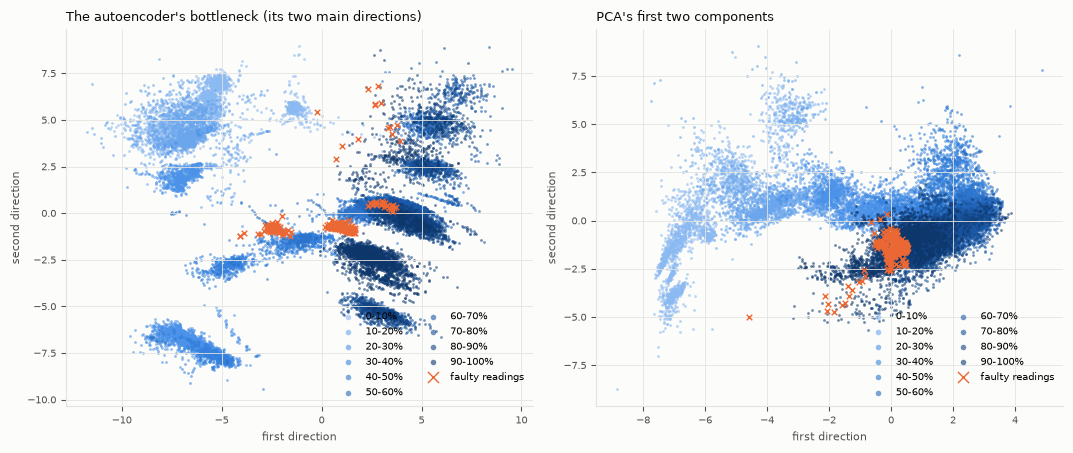

In [6]:
views = deepdive.bottleneck()
print("Bottleneck size:", views["bottleneck size"])
plots.two_views({"The autoencoder's bottleneck (its two main directions)": views["autoencoder"],
                 "PCA's first two components": views["PCA"]}, views["stage"], tenths, every=3);

**What this shows.** **In the autoencoder's bottleneck, the normal readings stay as separate islands**, one per stage, and the faulty readings sit in the gaps between them. **In PCA's first two components the islands merge into one cloud**, and the faulty readings sit inside it. A flat surface cannot keep apart islands that do not lie on a line; a network with a bend can.

## 3. Which ingredient is it?

*Fixed before computing* (see the top of the notebook). Each test is scored exactly like the autoencoder: per-sensor errors scaled by their 99th percentile on the same held-aside batches, combined the same way, judged with the same alarm line. Catch rates are the mean over three seeds where the model has seeds. The gap to the autoencoder has its range from resampling batches. *Share of the gap closed* is how far a test gets from PCA scored alike (a straight line, nothing added: 0) to the autoencoder (1).

*Added after section 1:* the straight-link and curved-link detectors **scored exactly like the autoencoder** (fitted on the same training part, scaled on the same held-aside batches), to test whether the scoring explains the curved-link's miss.

In [7]:
deepdive.score_ingredients()      # about 30 minutes the first time; then read from results/cache
ingredients = deepdive.ingredient_table()
display(ingredients[[c for c in ingredients.columns if c.startswith("the 3")]])
ingredients[[c for c in ingredients.columns if c.startswith("all 10")]]

,the 3 substrate feed batches: caught,"the 3 substrate feed batches: gap to the autoencoder, points",the 3 substrate feed batches: range,the 3 substrate feed batches: share of the gap closed
model,,,,
Autoencoder,0.379,0,,1
"PCA, scored like the autoencoder",0,-37.935,-64.0 to -24.2,0
Curved-link residual,0.01,-36.925,-62.7 to -23.1,0.027
PCA + corners (hinge terms),0.14,-23.962,-49.0 to +7.9,0.368
PCA + switches (on/off columns),0.002,-37.767,-63.9 to -24.2,0.004
PCA per stage,0.069,-31.033,-41.8 to +0.3,0.182
PCA per control strategy,0.002,-37.767,-63.9 to -24.2,0.004
"Autoencoder, measurements only",0.006,-37.318,-63.4 to -23.6,0.016
"Autoencoder, outputs only",0.611,23.176,+3.0 to +34.7,1.611


,all 10 batches: caught,"all 10 batches: gap to the autoencoder, points",all 10 batches: range,all 10 batches: share of the gap closed
model,,,,
Autoencoder,0.639,0,,1
"PCA, scored like the autoencoder",0.285,-35.43,-54.4 to -17.6,0
Curved-link residual,0.451,-18.79,-35.8 to -5.8,0.47
PCA + corners (hinge terms),0.352,-28.742,-47.6 to -5.6,0.189
PCA + switches (on/off columns),0.363,-27.627,-43.6 to -14.1,0.22
PCA per stage,0.304,-33.519,-48.6 to -9.7,0.054
PCA per control strategy,0.286,-35.35,-55.2 to -17.3,0.002
"Autoencoder, measurements only",0.39,-24.947,-39.0 to -13.2,0.296
"Autoencoder, outputs only",0.461,-17.834,-51.1 to +7.2,0.497


**What this shows.**

- **Which sensors names the ingredient.** The autoencoder trained on the **11 controller outputs only** catches **0.61** of the three batches' faulty readings, more than the full autoencoder (0.38): +23 points (+3 to +35). Trained on the **9 measurements only**, it catches **0.01**. The win lives in the joint values of the controller outputs.
- **Corners close about a third of the gap** on the three batches (PCA with hinge terms: 0.14 against 0.38). Hinges let a flat model bend at a few places on each output, which roughly marks out some of the islands.
- **Stages close about a fifth** (a separate PCA per tenth of the batch: 0.07). Within a tenth the outputs still step.
- **Switches and strategies close nothing** (0.00).
- **Scoring is not the difference.** The curved-link scored exactly like the autoencoder catches 0.06 of the three batches (0.43 of all ten). Predicting the sugar feed from the other sensors leaves wider errors on normal data than rebuilding it through the autoencoder's bottleneck.
- On all ten batches the autoencoder stays ahead of every *ingredient* test. (*Round 3:* the last four rows are the schedule-aware checks; see section 6.) The outputs-only autoencoder (0.46) is behind it there: the other faults show partly in the measurements.

## 4. What the autoencoder learned, and what the fault does

The six stepped controller outputs and two measurements over a batch: the 20 normal recipe fit batches (blue) and the three substrate feed batches (orange). The 76-92 hour stretch is shaded.

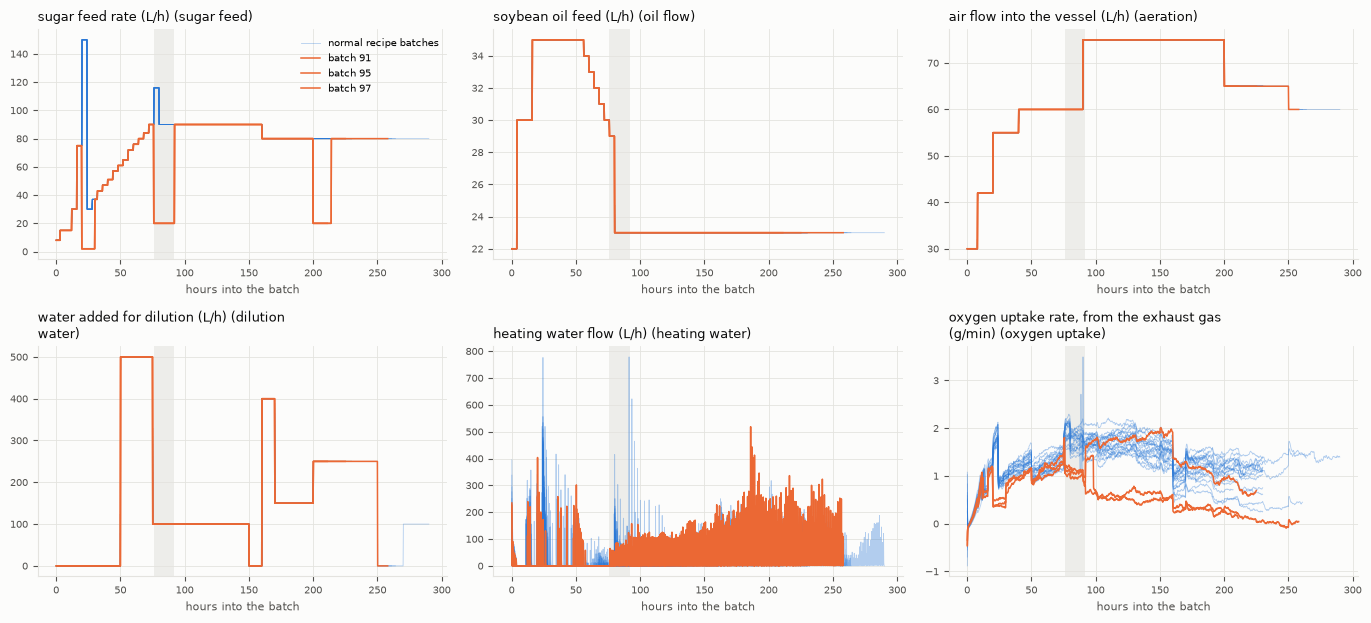

In [8]:
deepdive.schedule_plot();

Three tables behind the write-up: how the controller outputs step; how many combinations the six stepped outputs take, and whether the faulty readings fall on one; and how far each sensor moves during 76-92 hours in the three batches, against the normal recipe batches at the same hours (in units of their batch-to-batch spread).

In [9]:
display(deepdive.output_steps())
display(deepdive.joint_states())
deepdive.measurement_response()

,distinct values (all fit batches),distinct values (recipe fit batches),changes per recipe batch (median),share at commonest value
controller output,,,,
aeration,6,6,5,0.48
sugar feed,23,18,20,0.356
acid flow,808,353,21,0.978
base flow,46680,19357,1115.5,0.027
cooling water,52104,20124,1108.5,0.042
heating water,33268,11837,655.5,0.451
dilution water,6,6,6,0.333
head pressure,6,6,6,0.381
broth dumped,2,2,12,0.947


,value
combinations in the 60 normal fit batches,19523
combinations in the recipe fit batches,36
faulty readings whose combination occurs in normal data,0
faulty readings whose aeration value occurs in normal data,1
faulty readings whose sugar feed value occurs in normal data,0
faulty readings whose dilution water value occurs in normal data,1
faulty readings whose head pressure value occurs in normal data,1
faulty readings whose PAA flow value occurs in normal data,1
faulty readings whose oil flow value occurs in normal data,1


,batch 91,batch 95,batch 97,mean shift (spreads)
sensor,,,,
heating water,72.17,49.419,58.21,59.933
O2 off-gas,4.276,4.858,4.012,4.382
oxygen uptake,-4.208,-4.756,-3.92,-4.295
CO2 evolution,-2.622,-3.381,-2.65,-2.884
CO2 off-gas,-2.438,-3.214,-2.472,-2.708
dissolved oxygen,1.736,2.92,2.557,2.404
base flow,-1.179,-2.157,-1.492,-1.61
weight,-2.67,-2.085,0.146,-1.536
volume,-1.598,-1.875,0.39,-1.028


**What the autoencoder learned.** In a recipe batch, six controller outputs step through a fixed schedule: the sugar feed, the oil feed, the air flow, the dilution water, the head pressure and the precursor (PAA) flow. In the recipe batches each takes 4 to 18 values and changes 3 to 20 times per batch. The values go up and down, not in order, and different outputs change at different hours. Together the six take only **36 combinations** in the recipe batches: islands in the space of controller outputs. The autoencoder learned these islands. A reading on an island passes through its bottleneck almost unchanged; a reading off every island is pulled to the nearest one, and the difference is a large error.

**Why a straight model misses it.** The 36 islands do not lie on any flat surface. A straight model (PCA, the straight-link detector) has to fit one flat surface through all of them, so on normal data its errors are already wide. The fault's readings sit close to that surface, and their errors stay inside those wide lines (PCA scored alike: 0.6 of its line on the sugar feed). Hinge terms (corners) give it some bends and recover about a third of the gap.

**What the fault does.** For 16 hours the sugar feed is held at 20 L/h. That value is inside its normal range (8 to 150 L/h) but is never one of the recipe's steps (it uses 15 and 30), and at that hour the other five outputs sit on the island where the sugar feed is 90. So the reading sits between islands (none of the 257 faulty readings falls on a normal combination). The process reacts: oxygen uptake and CO2 fall (about 3 to 4 spreads), the dissolved oxygen rises, and the heating water switches on (it is normally off then). But the measurements move **together**, as they would at a calmer stage of the batch. They stay on their own normal surface, which is why the measurements-only autoencoder sees nothing. The batch never fully recovers: oxygen uptake stays lower for the rest of it.

**Why the other two stretches are missed.** At 200-214 hours the autoencoder does see the sugar feed as off (1.3 to 1.6 times its line on average), but the largest scaled error stays just under the alarm line (1.8), except in parts of batch 97. At 20-30 hours its sugar-feed error is only about half its line, although the recipe's feed there is 30 to 150 L/h; why this early stretch hides the fault from the autoencoder is not worked out here.

## 5. A recipe for artificial data that should reproduce it

The smallest description of the data structure and of the fault, for part D of the follow-up round:

- **Sensors.** About 6 controller outputs that each step through a fixed schedule over a batch: 4 to 20 distinct values, steps at different times for different outputs, values going up and down. Plus about 6 measurements that follow the process smoothly: activity rises and falls over the batch, the measurements follow it with a lag, and with noise of a few percent.
- **Batches.** Every batch follows the same schedule on its own clock: the length varies by about 10%, and the step times stretch with it. Small batch-to-batch differences in the measurements, and a slow, harmless drift.
- **The ingredient.** The joint values of the stepped outputs sit on a few dozen islands that no flat surface passes through. No smooth curve is needed. *The strength of the ingredient* is how far the islands are from a flat surface: if every output were a straight ramp over the batch, the islands would line up and a straight model would see everything.
- **The fault.** One stepped output is held for a stretch at a value inside its normal range that the schedule does not use at that time (between its own steps), while the other outputs keep to the schedule. The measurements respond as if the batch had moved to a calmer stage: together, along their normal surface, with a lag. A per-sensor check misses it (the value is in range), a straight model misses it (the reading lies near its flat surface), and a model that learns the islands sees it.

## 6. Round 3: simple checks that know the schedule

*Added in round 3, after everything above.* The tables in sections 1 and 3 now include three simple, schedule-aware checks, defined before they were computed (notebook 09, section 12): an **unseen value check** (was each stepped output's value ever seen in normal fitting batches?), the **nearest normal reading** (how far the controller outputs are from the closest normal reading), and **recipe at this hour** (how far each output is from the recipe batches' median at the same hour).

**What this shows. A lookup of normal values does the autoencoder's job, and more.** On the three substrate feed batches the unseen value check alarms on **every** faulty reading, in all three stretches: neither 2 nor 20 L/h is a value the recipe ever uses. The nearest normal reading catches the 76-92 h and 200-214 h stretches whole and about half of the 20-30 h one. The autoencoder catches the middle stretch only. In the ingredient table, on the three batches, the unseen value check catches 1.00 and the nearest normal reading 0.88, against the autoencoder's 0.38; on all ten batches the unseen value check ties the autoencoder (0.645 against 0.639).

**So the recipe of section 5 needs one line more.** It still describes what makes a *straight-line* model miss this fault: the controller outputs sit on islands that no flat surface passes through. But what the autoencoder learned, which values and combinations are normal, a simple lookup learns too. In this fault the held value is also one the recipe never uses, which a lookup catches at once. Round 3 tests a held value the recipe *does* use (fault B of notebook 13) and the generator against these checks (notebook 12).